# Part 5: A Time-Varying Risk-Free Rate

### Ramith Vaid | NTU Singapore

Every optimizer and every Sharpe ratio so far has used a fixed 2% risk-free rate. Over the sample the 13-week Treasury bill yield ran from about 0% (2014 to 2015, 2020 to 2021) to over 5% (2023 to 2024), so a fixed 2% is far from the rate an investor actually faced for much of the period. The rate enters in two places, and this part changes each separately:

1. **In the optimizer.** Max Sharpe maximizes `(w'mu - rf) / vol`. A different `rf` can change which portfolio is chosen. Here each window's optimizer uses the 13-week T-bill yield on the last training day (the rate available when the portfolio is chosen), instead of 2%.
2. **In measuring performance.** A Sharpe ratio against 2% over-states performance when bills yield 5% and under-states it when they yield 0%. Here Sharpe is also computed against the T-bill return actually earned over the same days (geometric return minus the compounded T-bill return, divided by volatility).

The rate series is `^IRX` from Yahoo Finance (annualized yield in percent, floored at zero). Everything else is as in Part 3: 15 rolling windows, 5-year training, 6-month test, 35% cap, buy-and-hold inside a window, 10 bps cost per unit traded, cost-blind Max Sharpe. Both the 8-stock universe and the 13-asset universe from Part 4 are run. The data end date is pinned to 2026-10-13.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    max_sharpe_portfolio, load_or_build_window_inputs, window_risk_free, simulate_strategy_rf, performance_vs_risk_free
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data and the risk-free series

In [2]:
tickers8 = ['JPM', 'AAPL', 'XOM', 'JNJ', 'PG', 'CAT', 'NEE', 'AMZN']
tickers13 = tickers8 + ['VNQ', 'TLT', 'EFA', 'EEM', 'GLD']
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
prices = pd.DataFrame({t: yf.download(t, start=START, end=END, progress=False)['Close'].squeeze() for t in tickers13}).dropna()
log_returns = np.log(prices / prices.shift(1)).dropna()

irx = yf.download('^IRX', start=START, end=END, progress=False)['Close'].squeeze().dropna()
tbill_annual = (irx / 100).clip(lower=0.0).reindex(log_returns.index).ffill().bfill()
rf_daily = tbill_annual / 252
print(f'{len(log_returns)} trading days; T-bill yield: mean {tbill_annual.mean()*100:.2f}%, min {tbill_annual.min()*100:.2f}%, max {tbill_annual.max()*100:.2f}%')
print()
print('Average 13-week T-bill yield by year (%):')
print((tbill_annual.groupby(tbill_annual.index.year).mean() * 100).round(2).to_string())

3213 trading days; T-bill yield: mean 1.92%, min 0.00%, max 5.35%

Average 13-week T-bill yield by year (%):
Date
2014    0.02
2015    0.04
2016    0.30
2017    0.92
2018    1.92
2019    2.04
2020    0.34
2021    0.03
2022    2.00
2023    5.05
2024    4.95
2025    4.05
2026    3.68


In [3]:
inputs8 = load_or_build_window_inputs('cache_window_inputs_8.pkl', log_returns, tickers8)
inputs13 = load_or_build_window_inputs('cache_window_inputs_13.pkl', log_returns, tickers13)
rf_w = window_risk_free(inputs8, log_returns, tbill_annual)
print('Risk-free rate used by each window\'s optimizer (T-bill yield on the last training day):')
print(pd.DataFrame({'window': [w['window'] for w in inputs8], 'test_start': [w['test_start'] for w in inputs8],
                    'rf_%': np.round(np.array(rf_w) * 100, 2)}).to_string(index=False))

Risk-free rate used by each window's optimizer (T-bill yield on the last training day):
 window test_start  rf_%
      1 2019-01-07  2.36
      2 2019-07-09  2.18
      3 2020-01-07  1.49
      4 2020-07-08  0.14
      5 2021-01-06  0.08
      6 2021-07-08  0.04
      7 2022-01-05  0.08
      8 2022-07-08  1.85
      9 2023-01-06  4.50
     10 2023-07-11  5.22
     11 2024-01-09  5.22
     12 2024-07-11  5.22
     13 2025-01-10  4.20
     14 2025-07-15  4.23
     15 2026-01-13  3.53


## 2. How sensitive is the Max Sharpe portfolio to the risk-free rate?

Full-sample Max Sharpe weights (8 stocks, GARCH-informed covariance, 35% cap) at three risk-free rates, before any rolling analysis. If the weights barely move, the rate in the optimizer matters little and the measurement side is what counts.

In [4]:
from portfolio_utils import build_garch_covariance
mean_full = log_returns[tickers8].mean() * 252
cov_full, _ = build_garch_covariance(log_returns[tickers8], tickers8)
W = {rf: max_sharpe_portfolio(mean_full, cov_full, 8, rf=rf) for rf in (0.0, 0.02, 0.05)}
tab = pd.DataFrame({f'rf={int(rf*100)}%': w for rf, w in W.items()}, index=tickers8) * 100
print(tab.round(1).to_string())
print()
print(f'Sum of absolute weight changes (percentage points): rf 0% -> 2%: {np.abs(W[0.0] - W[0.02]).sum()*100:.1f}, '
      f'2% -> 5%: {np.abs(W[0.02] - W[0.05]).sum()*100:.1f}')

      rf=0%  rf=2%  rf=5%
JPM    35.0   35.0   35.0
AAPL   35.0   35.0   35.0
XOM     0.0    0.0    0.0
JNJ     5.0    3.6    0.0
PG      0.0    0.0    0.0
CAT     0.0    0.0    1.4
NEE    23.3   23.5   23.6
AMZN    1.7    2.9    5.1

Sum of absolute weight changes (percentage points): rf 0% -> 2%: 2.8, 2% -> 5%: 7.2


## 3. Rolling comparison: fixed 2% against the window's T-bill yield

For each universe and covariance method, the strategy is run twice: with the optimizer's rate fixed at 2% (as before) and with each window's own T-bill yield. Both are scored net of 10 bps costs, with Sharpe computed against 2% (the earlier convention) and against the T-bill return actually earned.

In [5]:
COST = 0.0010
KEYS = [('sample', 'Sample'), ('garch_static', 'GARCH + static corr'), ('garch_dcc', 'GARCH + DCC corr'), ('equal_weight', 'Equal weight (1/N)')]
rows, weights_store = [], {}
for uni, inputs, n in (('8 US stocks', inputs8, 8), ('13 assets', inputs13, 13)):
    rf_win = window_risk_free(inputs, log_returns, tbill_annual)
    for key, label in KEYS:
        for rf_mode, rf_list in (('fixed 2%', [0.02] * len(inputs)), ('window T-bill', rf_win)):
            wdf, net, gross, W_ = simulate_strategy_rf(inputs, n, key, COST, rf_list)
            p = performance_vs_risk_free(net, rf_daily)
            weights_store[(uni, key, rf_mode)] = W_
            rows.append({'universe': uni, 'strategy': label, 'optimizer_rf': rf_mode, 'net_return_%': p['ann_return'] * 100,
                         'vol_%': p['ann_vol'] * 100, 'avg_tbill_%': p['avg_tbill'] * 100, 'sharpe_vs_2%': p['sharpe_fixed'],
                         'sharpe_vs_tbill': p['sharpe_tbill'], 'avg_turnover': wdf['turnover'].iloc[1:].mean()})
perf = pd.DataFrame(rows)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(perf.to_string(index=False))

   universe            strategy  optimizer_rf  net_return_%  vol_%  avg_tbill_%  sharpe_vs_2%  sharpe_vs_tbill  avg_turnover
8 US stocks              Sample      fixed 2%        18.662 21.061        2.737         0.791            0.756         0.385
8 US stocks              Sample window T-bill        19.278 21.142        2.737         0.817            0.782         0.383
8 US stocks GARCH + static corr      fixed 2%        19.117 20.084        2.737         0.852            0.816         0.581
8 US stocks GARCH + static corr window T-bill        20.026 20.054        2.737         0.899            0.862         0.578
8 US stocks    GARCH + DCC corr      fixed 2%        18.629 19.463        2.737         0.854            0.816         0.549
8 US stocks    GARCH + DCC corr window T-bill        19.517 19.572        2.737         0.895            0.857         0.556
8 US stocks  Equal weight (1/N)      fixed 2%        21.672 17.847        2.737         1.102            1.061         0.114


### How much do the chosen weights change?

Per window, half the sum of absolute weight differences between the fixed-2% portfolio and the T-bill-rate portfolio (the share of the portfolio that is different), averaged over the 15 windows, and the number of windows in which the two are identical to within 0.1 percentage point.

In [6]:
rows = []
for uni in ('8 US stocks', '13 assets'):
    for key, label in KEYS[:3]:
        a, b = weights_store[(uni, key, 'fixed 2%')], weights_store[(uni, key, 'window T-bill')]
        d = 0.5 * np.abs(a - b).sum(axis=1)
        rows.append({'universe': uni, 'strategy': label, 'mean_share_of_portfolio_different_%': d.mean() * 100,
                     'max_%': d.max() * 100, 'windows_identical': int((d < 0.001).sum()), 'windows': len(d)})
wdiff = pd.DataFrame(rows)
print(wdiff.to_string(index=False))

   universe            strategy  mean_share_of_portfolio_different_%  max_%  windows_identical  windows
8 US stocks              Sample                                2.248  8.699                  2       15
8 US stocks GARCH + static corr                                4.405  7.828                  1       15
8 US stocks    GARCH + DCC corr                                3.844  7.857                  1       15
  13 assets              Sample                                4.690 16.149                  0       15
  13 assets GARCH + static corr                                4.408 10.409                  0       15
  13 assets    GARCH + DCC corr                                4.003  8.616                  0       15


## 4. Does the choice change any conclusion?

Three checks: whether the ordering of the strategies changes between the fixed and the time-varying optimizer; how much the Sharpe ratios move when measured against the actual T-bill return instead of 2%; and the per-window excess return of each strategy over the T-bill.

In [7]:
for uni in ('8 US stocks', '13 assets'):
    p = perf[perf.universe == uni]
    print(f'--- {uni} ---')
    for col in ('sharpe_vs_2%', 'sharpe_vs_tbill'):
        for mode in ('fixed 2%', 'window T-bill'):
            s = p[(p.optimizer_rf == mode)].set_index('strategy')[col].sort_values(ascending=False)
            print(f'  {col:<16} optimizer rf = {mode:<14}: ' + ' > '.join(f'{k} {v:.3f}' for k, v in s.items()))
    chg = p.pivot(index='strategy', columns='optimizer_rf', values='sharpe_vs_tbill')
    print('  change in Sharpe vs T-bill from using the window T-bill in the optimizer:',
          (chg['window T-bill'] - chg['fixed 2%']).round(3).to_dict())
    gap = p[p.optimizer_rf == 'fixed 2%'].set_index('strategy')
    print('  Sharpe vs 2% minus Sharpe vs T-bill (measurement effect):', (gap['sharpe_vs_2%'] - gap['sharpe_vs_tbill']).round(3).to_dict())
    print()

--- 8 US stocks ---
  sharpe_vs_2%     optimizer rf = fixed 2%      : Equal weight (1/N) 1.102 > GARCH + DCC corr 0.854 > GARCH + static corr 0.852 > Sample 0.791
  sharpe_vs_2%     optimizer rf = window T-bill : Equal weight (1/N) 1.102 > GARCH + static corr 0.899 > GARCH + DCC corr 0.895 > Sample 0.817
  sharpe_vs_tbill  optimizer rf = fixed 2%      : Equal weight (1/N) 1.061 > GARCH + DCC corr 0.816 > GARCH + static corr 0.816 > Sample 0.756
  sharpe_vs_tbill  optimizer rf = window T-bill : Equal weight (1/N) 1.061 > GARCH + static corr 0.862 > GARCH + DCC corr 0.857 > Sample 0.782
  change in Sharpe vs T-bill from using the window T-bill in the optimizer: {'Equal weight (1/N)': 0.0, 'GARCH + DCC corr': 0.041, 'GARCH + static corr': 0.047, 'Sample': 0.026}
  Sharpe vs 2% minus Sharpe vs T-bill (measurement effect): {'Sample': 0.035, 'GARCH + static corr': 0.037, 'GARCH + DCC corr': 0.038, 'Equal weight (1/N)': 0.041}

--- 13 assets ---
  sharpe_vs_2%     optimizer rf = fixed 2%     

## 5. Chart

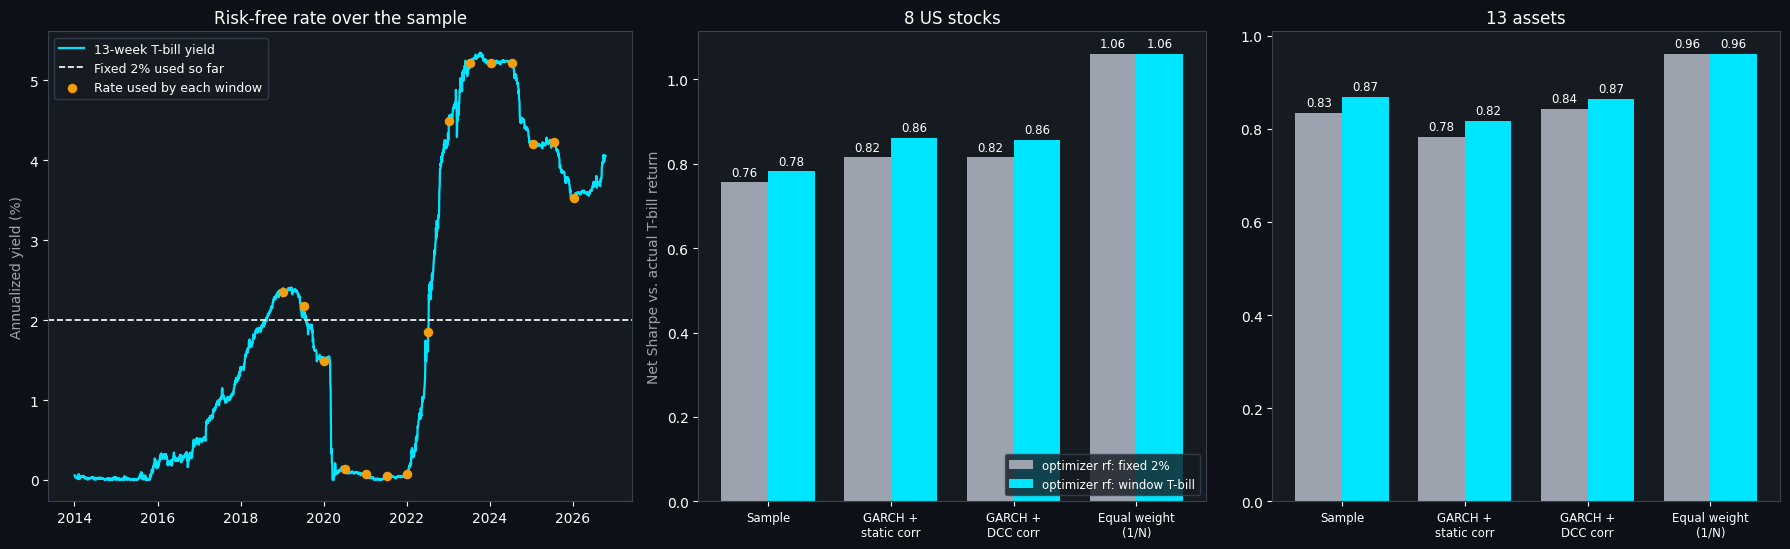

Saved chart_part5_risk_free.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={'width_ratios': [1.15, 1, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
ax = axes[0]
ax.plot(tbill_annual.index, tbill_annual * 100, color='#00e5ff', lw=1.6, label='13-week T-bill yield')
ax.axhline(2, color='white', ls='--', lw=1.2, label='Fixed 2% used so far')
ax.scatter([pd.Timestamp(w['test_start']) for w in inputs8], np.array(rf_w) * 100, color='#f59e0b', s=34, zorder=3, label='Rate used by each window')
ax.set_ylabel('Annualized yield (%)', color='#9ca3af')
ax.set_title('Risk-free rate over the sample', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9, loc='upper left')

ax = axes[1]
p = perf[(perf.universe == '8 US stocks')]
labels = [l for _, l in KEYS]
x = np.arange(len(labels))
w = 0.38
for off, mode, col in ((-w/2, 'fixed 2%', '#9ca3af'), (w/2, 'window T-bill', '#00e5ff')):
    vals = [p[(p.strategy == l) & (p.optimizer_rf == mode)]['sharpe_vs_tbill'].iloc[0] for l in labels]
    bars = ax.bar(x + off, vals, w, color=col, label=f'optimizer rf: {mode}')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.015, f'{v:.2f}', ha='center', fontsize=8.5, color='white')
ax.set_xticks(x)
ax.set_xticklabels([l.replace(' + ', ' +\n').replace(' (', '\n(') for l in labels], color='white', fontsize=8.5)
ax.set_ylabel('Net Sharpe vs. actual T-bill return', color='#9ca3af')
ax.set_title('8 US stocks', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5, loc='lower right')

ax = axes[2]
p = perf[(perf.universe == '13 assets')]
for off, mode, col in ((-w/2, 'fixed 2%', '#9ca3af'), (w/2, 'window T-bill', '#00e5ff')):
    vals = [p[(p.strategy == l) & (p.optimizer_rf == mode)]['sharpe_vs_tbill'].iloc[0] for l in labels]
    bars = ax.bar(x + off, vals, w, color=col, label=f'optimizer rf: {mode}')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.015, f'{v:.2f}', ha='center', fontsize=8.5, color='white')
ax.set_xticks(x)
ax.set_xticklabels([l.replace(' + ', ' +\n').replace(' (', '\n(') for l in labels], color='white', fontsize=8.5)
ax.set_title('13 assets', color='white', fontsize=12)
plt.tight_layout()
plt.savefig('chart_part5_risk_free.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part5_risk_free.png')

## 6. Summary and saved tables

In [9]:
perf.to_csv('part5_risk_free_comparison.csv', index=False)
wdiff.to_csv('part5_weight_differences.csv', index=False)
pd.DataFrame({'window': [w['window'] for w in inputs8], 'test_start': [w['test_start'] for w in inputs8], 'rf_used': rf_w}).to_csv('part5_window_rf.csv', index=False)
tab.to_csv('part5_fullsample_weights_by_rf.csv')
print('=' * 70)
print('PART 5 SUMMARY: TIME-VARYING RISK-FREE RATE')
print('=' * 70)
print(perf.to_string(index=False))
print()
print(wdiff.to_string(index=False))
print()
print('Files saved: chart_part5_risk_free.png, part5_risk_free_comparison.csv, part5_weight_differences.csv, part5_window_rf.csv, part5_fullsample_weights_by_rf.csv')

PART 5 SUMMARY: TIME-VARYING RISK-FREE RATE
   universe            strategy  optimizer_rf  net_return_%  vol_%  avg_tbill_%  sharpe_vs_2%  sharpe_vs_tbill  avg_turnover
8 US stocks              Sample      fixed 2%        18.662 21.061        2.737         0.791            0.756         0.385
8 US stocks              Sample window T-bill        19.278 21.142        2.737         0.817            0.782         0.383
8 US stocks GARCH + static corr      fixed 2%        19.117 20.084        2.737         0.852            0.816         0.581
8 US stocks GARCH + static corr window T-bill        20.026 20.054        2.737         0.899            0.862         0.578
8 US stocks    GARCH + DCC corr      fixed 2%        18.629 19.463        2.737         0.854            0.816         0.549
8 US stocks    GARCH + DCC corr window T-bill        19.517 19.572        2.737         0.895            0.857         0.556
8 US stocks  Equal weight (1/N)      fixed 2%        21.672 17.847        2.737  